# 42 - Long retain-only fine-tuning: does a memorized subpopulation erode?

The edit-then-fine-tune methods end their ten retain epochs with the forget cells fitted almost as well
as the baseline fits them (notebook 41, Part A), and retain-only fine-tuning alone drifts them only part
of the way toward the retrained models' level. This notebook runs the retain fine-tune on for far longer
and measures the forget cells every few epochs with the same instruments as notebook 41 (deterministic
negative ELBO, the canonical attacker, the reference audit).

**Part A, PBMC-33k cluster 13.** The 30 megakaryocytes sit inside a region the retain set keeps alive
(their nearest never-seen neighbours are fitted at about 290 by baseline and retrained models alike).
Three seeds, 200 epochs, Adam 1e-4, the methods' own learning rate.

**Part B, TCGA-BRCA Basal.** The 158 Basal patients are 17 percent of training and nothing like them
remains in the retain set. Same loop, same seeds, with the 30 unseen Basal patients tracked as well.

If the megakaryocyte fit keeps drifting toward the retrained level, the signal-intact mode is a budget
question and a controller still has no way to know when to stop. If it plateaus above that level, the
retain set is holding the subpopulation in place and no amount of retain fine-tuning removes it.

In [1]:
import sys
sys.path.insert(0, '../src')
sys.path.insert(0, '../scripts')

import json
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

import eval_multiseed as EM
EM.DEVICE = 'cpu'   # MIA scoring is CPU throughout
from eval_multiseed import (load_vae_model, train_fresh_attacker, evaluate_utility, MARKER_GENES,
                            DATA_PATH, SPLIT_PATH, MATCHED_NEG_PATH, BASELINE_CHECKPOINT)
from train_targeted_unlearn import Evaluator
from likelihood_audit import neg_elbo_per_cell as audit_neg_elbo
from long_finetune import long_retain_finetune

plt.style.use('seaborn-v0_8-whitegrid')
TRAIN_DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
OUTPUT_DIR = Path('../outputs/p8')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEEDS = [42, 123, 456]
EPOCHS, EVAL_EVERY, LR = 200, 5, 1e-4
levels = json.load(open('../outputs/p7/calibration_levels.json'))['mean_neg_elbo']
ltu = json.load(open('../outputs/p7/targeted_unlearning.json'))
pbmc_retrain_forget = np.mean([v['forget'] for k, v in levels.items() if k.startswith('retrain_clean')])
pbmc_lr_band = ltu['retrain_vs_retrain_lr_band']
print(f'training device: {TRAIN_DEVICE}; PBMC retrained-model forget level {pbmc_retrain_forget:.1f}; audit band {pbmc_lr_band}')

training device: mps; PBMC retrained-model forget level 337.2; audit band [0.2422680412371134, 0.5230240549828178]


## Part A: PBMC-33k cluster 13

In [2]:
adata = sc.read_h5ad(DATA_PATH)
split = json.load(open(SPLIT_PATH))
forget_idx, retain_idx, unseen_idx = split['forget_indices'], split['retain_indices'], split['unseen_indices']
matched_idx = json.load(open(MATCHED_NEG_PATH))['matched_indices']
X = torch.tensor(adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X, dtype=torch.float32)
X_forget, X_matched, X_retain = X[forget_idx], X[matched_idx], X[retain_idx]
X_holdout, labels_holdout = X[unseen_idx], adata.obs['leiden'].values[unseen_idx]
gene_names = list(adata.var_names)
marker_idx = [gene_names.index(g) for g in MARKER_GENES if g in gene_names]
rs = np.random.RandomState(42).choice(retain_idx, 5000, replace=False)
X_retain_sample = X[rs]

baseline, _ = load_vae_model(str(BASELINE_CHECKPOINT))
reference, _ = load_vae_model('../outputs/p1/retrain_clean/seed_42/best_model.pt')
attacker = train_fresh_attacker(baseline, adata, forget_idx, matched_idx, retain_idx)
attacker.eval()
evaluator = Evaluator(attacker, reference, X_forget, X_matched, X_retain_sample, 'cpu',
                      extra_sets={'unseen': X_holdout[:2000]})
neighbors_all = torch.arange(len(X_matched)).repeat(len(X_forget), 1)
print(f'forget {len(forget_idx)}, matched {len(matched_idx)}, retain {len(retain_idx)}')

Training fresh attacker on baseline F vs matched:
  Samples: 224 (30 forget + 194 matched)
  Features: 70 dims
  Train: 179, Test: 45


  Baseline AUC (F vs matched, full set): 0.8017
  (Canonical NB03 value: ~0.769)
forget 30, matched 194, retain 28094


In [3]:
pbmc_dir = OUTPUT_DIR / 'pbmc'
pbmc_dir.mkdir(exist_ok=True)
hist_pbmc, final_pbmc = {}, {}
for sd in SEEDS:
    out = pbmc_dir / f'seed{sd}'
    if (out / 'final_model.pt').exists():
        ck = torch.load(out / 'final_model.pt', map_location='cpu', weights_only=False)
        hist_pbmc[sd] = ck['history']
        final_pbmc[sd], _ = load_vae_model(str(out / 'final_model.pt'))
        print(f'seed {sd}: loaded')
        continue
    print(f'=== PBMC seed {sd} ===')
    model, hist = long_retain_finetune(baseline, X_retain, evaluator, neighbors_all, TRAIN_DEVICE,
                                       epochs=EPOCHS, lr=LR, batch_size=256, eval_every=EVAL_EVERY, seed=sd)
    out.mkdir(exist_ok=True)
    cfg = torch.load(BASELINE_CHECKPOINT, map_location='cpu', weights_only=False)['config']
    torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                'method': 'long_retain_finetune', 'epochs': EPOCHS, 'lr': LR, 'seed': sd}, out / 'final_model.pt')
    hist_pbmc[sd], final_pbmc[sd] = hist, model.to('cpu')

=== PBMC seed 42 ===


  epoch   0: forget=269.5 matched=333.1 retain=361.9 MLP=0.799 LR=0.996


  epoch   5: forget=279.8 matched=332.4 retain=361.5 MLP=0.770 LR=0.996


  epoch  10: forget=285.0 matched=332.5 retain=361.1 MLP=0.748 LR=0.996


  epoch  15: forget=289.3 matched=332.3 retain=360.9 MLP=0.746 LR=0.996


  epoch  20: forget=293.9 matched=332.2 retain=360.7 MLP=0.718 LR=0.996


... (114 outputs left out)

  epoch 185: forget=329.6 matched=332.3 retain=355.0 MLP=0.555 LR=0.591


  epoch 190: forget=328.4 matched=332.1 retain=355.0 MLP=0.568 LR=0.653


  epoch 195: forget=328.0 matched=331.9 retain=354.8 MLP=0.564 LR=0.609


  epoch 200: forget=331.3 matched=331.9 retain=354.5 MLP=0.561 LR=0.519


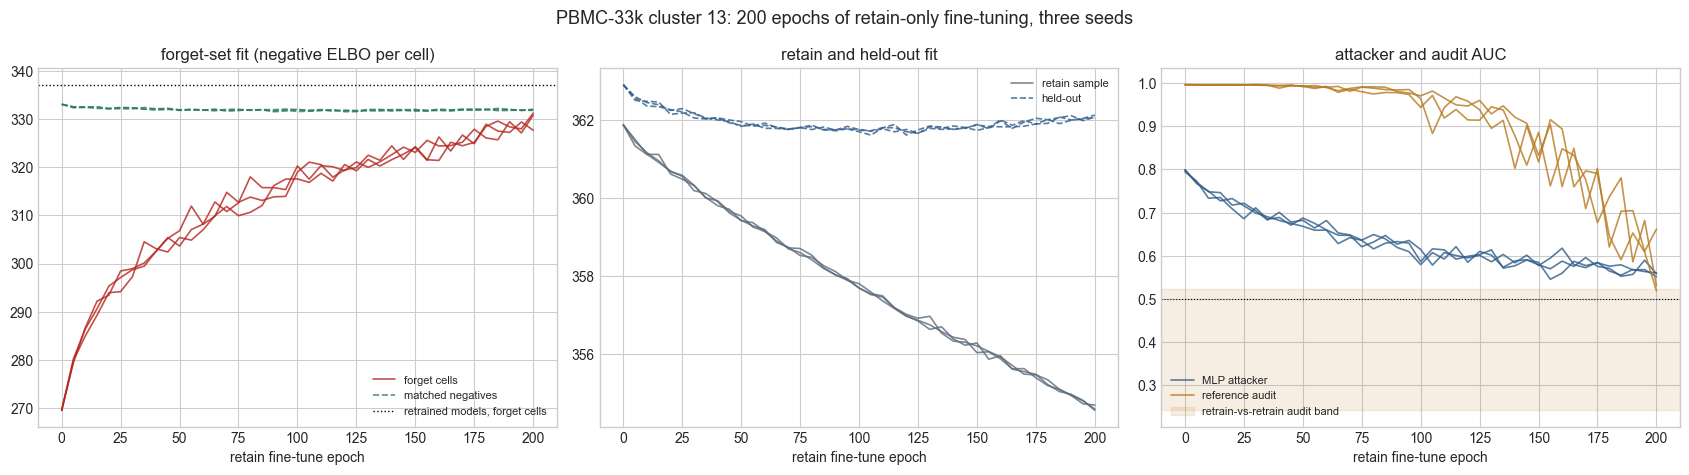

In [4]:
def curves(hists, retrain_level, lr_band, title, path, extra_key=None, extra_label=None):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for sd, h in hists.items():
        d = pd.DataFrame(h)
        axes[0].plot(d.epoch, d.forget_neg_elbo, color='#B3261E', alpha=0.8, lw=1.2, label='forget cells' if sd == list(hists)[0] else None)
        axes[0].plot(d.epoch, d.matched_neg_elbo, color='#2E7D5B', alpha=0.8, lw=1.2, ls='--', label='matched negatives' if sd == list(hists)[0] else None)
        if extra_key:
            axes[0].plot(d.epoch, d[extra_key], color='#7B3FA0', alpha=0.8, lw=1.2, ls='-.', label=extra_label if sd == list(hists)[0] else None)
        axes[1].plot(d.epoch, d.retain_neg_elbo, color='#5C6B7A', alpha=0.8, lw=1.2, label='retain sample' if sd == list(hists)[0] else None)
        axes[1].plot(d.epoch, d.unseen_neg_elbo, color='#2F5D8A', alpha=0.8, lw=1.2, ls='--', label='held-out' if sd == list(hists)[0] else None)
        axes[2].plot(d.epoch, d.mlp_auc, color='#2F5D8A', alpha=0.8, lw=1.2, label='MLP attacker' if sd == list(hists)[0] else None)
        axes[2].plot(d.epoch, d.lr_auc, color='#B7791F', alpha=0.8, lw=1.2, label='reference audit' if sd == list(hists)[0] else None)
    if retrain_level is not None:
        axes[0].axhline(retrain_level, color='k', lw=1, ls=':', label='retrained models, forget cells')
    if lr_band is not None:
        axes[2].axhspan(lr_band[0], lr_band[1], color='#B7791F', alpha=0.12, label='retrain-vs-retrain audit band')
    axes[2].axhline(0.5, color='k', lw=0.8, ls=':')
    axes[0].set_title('forget-set fit (negative ELBO per cell)'); axes[1].set_title('retain and held-out fit'); axes[2].set_title('attacker and audit AUC')
    for a in axes:
        a.set_xlabel('retain fine-tune epoch'); a.legend(fontsize=8)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

curves(hist_pbmc, pbmc_retrain_forget, pbmc_lr_band, 'PBMC-33k cluster 13: 200 epochs of retain-only fine-tuning, three seeds',
       OUTPUT_DIR / 'pbmc_long_finetune.png')

In [5]:
def checkpoints_table(hists, epochs=(0, 10, 50, 100, 200), cols=('forget_neg_elbo', 'matched_neg_elbo', 'retain_neg_elbo', 'mlp_auc', 'lr_auc')):
    rows = []
    for sd, h in hists.items():
        d = pd.DataFrame(h).set_index('epoch')
        for e in epochs:
            if e in d.index:
                rows.append({'seed': sd, 'epoch': e, **{c: d.loc[e, c] for c in cols if c in d.columns}})
    return pd.DataFrame(rows).set_index(['seed', 'epoch'])

util_rows = []
for sd, m in final_pbmc.items():
    u = evaluate_utility(m, X_holdout, labels_holdout, marker_idx, gene_names)
    util_rows.append({'seed': sd, 'elbo': u['elbo'], 'marker_r': u['marker_r'], 'ari': u['ari']})
pbmc_table = checkpoints_table(hist_pbmc)
print('held-out utility after 200 epochs:'); display(pd.DataFrame(util_rows).set_index('seed').round(3))
pbmc_table.round(3)

held-out utility after 200 epochs:


,elbo,marker_r,ari
seed,,,
42,363.252,0.832,0.406
123,363.099,0.832,0.423
456,363.131,0.832,0.425


forget_neg_elbo  matched_neg_elbo  retain_neg_elbo  mlp_auc  \
seed epoch                                                                
42   0              269.489           333.126          361.881    0.799   
     10             284.953           332.488          361.128    0.748   
     50             305.419           331.953          359.429    0.682   
     100            317.609           331.605          357.688    0.580   
     200            327.735           331.946          354.577    0.552   
123  0              269.489           333.126          361.881    0.799   
     10             286.669           332.491          361.169    0.750   
     50             306.824           331.850          359.540    0.669   
     100            320.295           332.027          357.799    0.587   
     200            330.830           332.094          354.678    0.559   
456  0              269.489           333.126          361.881    0.795   
     10             286.380           332.575          361.122    0.734   
     50             303.642           331.973          359.418    0.688   
     100            319.014           332.028          357.687    0.615   
     200            331.278           331.865          354.544    0.561   

            lr_auc  
seed epoch          
42   0       0.996  
     10      0.996  
     50      0.992  
     100     0.971  
     200     0.662  
123  0       0.996  
     10      0.995  
     50      0.993  
     100     0.944  
     200     0.531  
456  0       0.996  
     10      0.995  
     50      0.994  
     100     0.964  
     200     0.519

## Part B: TCGA-BRCA Basal (the contrast)

The retain set has no Basal patient. The reference is the TCGA retrained model (a single seed, so the
audit has no retrain-versus-retrain band here). The 30 unseen Basal patients are tracked alongside the
158 forget patients; the gap between the two is the per-patient membership signal in the likelihood.

In [6]:
adata_t = sc.read_h5ad('../data/tcga_brca/tcga_brca_processed.h5ad')
split_t = json.load(open('../outputs/tcga_brca/split_structured.json'))
f_t, r_t, u_t = split_t['forget_indices'], split_t['retain_indices'], split_t['unseen_indices']
m_t = json.load(open('../outputs/tcga_brca/matched_negatives.json'))['matched_indices']
basal_unseen = [i for i in u_t if adata_t.obs['subtype'].values[i] == 'Basal']
Xt = torch.tensor(adata_t.X.toarray() if hasattr(adata_t.X, 'toarray') else adata_t.X, dtype=torch.float32)
Xt_forget, Xt_matched, Xt_retain, Xt_unseen, Xt_basal_unseen = Xt[f_t], Xt[m_t], Xt[r_t], Xt[u_t], Xt[basal_unseen]

baseline_t, _ = load_vae_model('../outputs/tcga_brca/baseline/best_model.pt')
reference_t, _ = load_vae_model('../outputs/tcga_brca/retrain_structured/best_model.pt')
attacker_t = train_fresh_attacker(baseline_t, adata_t, f_t, m_t, r_t)
attacker_t.eval()
evaluator_t = Evaluator(attacker_t, reference_t, Xt_forget, Xt_matched, Xt_retain, 'cpu',
                        extra_sets={'unseen': Xt_unseen, 'unseen_basal': Xt_basal_unseen})
neighbors_t = torch.arange(len(Xt_matched)).repeat(len(Xt_forget), 1)
tcga_retrain_forget = float(audit_neg_elbo(reference_t, Xt_forget).mean())
tcga_retrain_basal_unseen = float(audit_neg_elbo(reference_t, Xt_basal_unseen).mean())
print(f'forget {len(f_t)} Basal, matched {len(m_t)} cross-subtype, unseen Basal {len(basal_unseen)}, retain {len(r_t)}; '
      f'retrained model fits forget at {tcga_retrain_forget:.1f}, unseen Basal at {tcga_retrain_basal_unseen:.1f}')

Training fresh attacker on baseline F vs matched:
  Samples: 247 (158 forget + 89 matched)
  Features: 70 dims
  Train: 197, Test: 50
  Baseline AUC (F vs matched, full set): 0.8035
  (Canonical NB03 value: ~0.769)


forget 158 Basal, matched 89 cross-subtype, unseen Basal 30, retain 767; retrained model fits forget at 1277.4, unseen Basal at 1246.4


=== TCGA seed 42 ===


  epoch   0: forget=1116.5 matched=790.9 retain=639.1 MLP=0.803 LR=0.833


  epoch   5: forget=1265.6 matched=842.9 retain=624.5 MLP=0.829 LR=0.576


  epoch  10: forget=1277.8 matched=847.7 retain=619.8 MLP=0.829 LR=0.338


  epoch  15: forget=1262.7 matched=838.8 retain=616.7 MLP=0.829 LR=0.552


  epoch  20: forget=1257.7 matched=833.8 retain=614.4 MLP=0.830 LR=0.546


... (80 outputs left out)

  epoch 175: forget=1155.6 matched=703.6 retain=483.4 MLP=0.849 LR=0.498
  epoch 180: forget=1158.5 matched=705.2 retain=483.3 MLP=0.847 LR=0.496


  epoch 185: forget=1151.4 matched=700.3 retain=480.8 MLP=0.848 LR=0.508


  epoch 190: forget=1115.8 matched=680.6 retain=474.4 MLP=0.851 LR=0.562
  epoch 195: forget=1074.4 matched=664.4 retain=468.9 MLP=0.846 LR=0.605


  epoch 200: forget=1023.8 matched=636.2 retain=455.6 MLP=0.843 LR=0.638


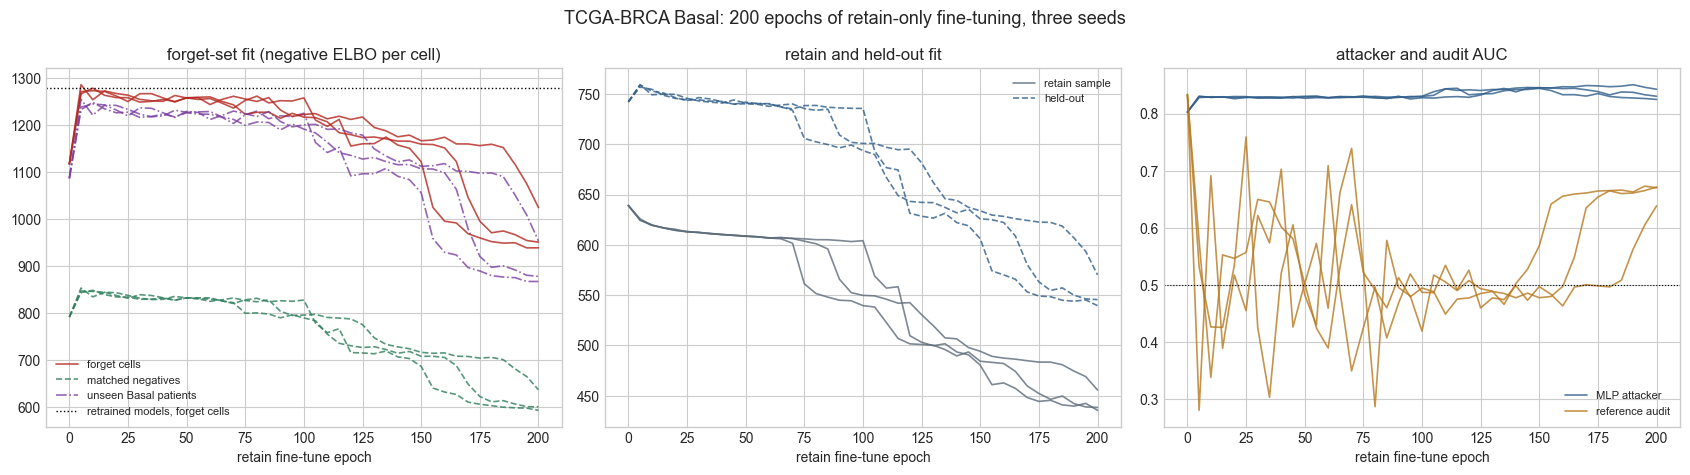

forget_neg_elbo  unseen_basal_neg_elbo  matched_neg_elbo  \
seed epoch                                                             
42   0             1116.538               1085.975           790.924   
     10            1277.792               1247.734           847.738   
     50            1257.053               1225.479           831.938   
     100           1257.113               1224.394           827.053   
     200            938.204                866.563           592.607   
123  0             1116.538               1085.975           790.924   
     10            1253.113               1220.401           833.897   
     50            1256.916               1226.368           831.675   
     100           1216.160               1190.694           789.139   
     200            950.293                877.404           599.907   
456  0             1116.538               1085.975           790.924   
     10            1272.388               1244.253           845.390   
     50            1257.529               1228.316           831.802   
     100           1221.974               1199.604           795.194   
     200           1023.792                952.929           636.237   

            retain_neg_elbo  mlp_auc  lr_auc  
seed epoch                                    
42   0              639.080    0.803   0.833  
     10             619.767    0.829   0.338  
     50             608.691    0.827   0.501  
     100            604.108    0.830   0.419  
     200            435.442    0.825   0.670  
123  0              639.080    0.803   0.833  
     10             619.429    0.828   0.691  
     50             608.419    0.829   0.503  
     100            539.525    0.830   0.494  
     200            438.281    0.830   0.671  
456  0              639.080    0.802   0.833  
     10             619.483    0.829   0.426  
     50             608.725    0.830   0.482  
     100            549.704    0.828   0.487  
     200            455.644    0.843   0.638

In [7]:
tcga_dir = OUTPUT_DIR / 'tcga'
tcga_dir.mkdir(exist_ok=True)
hist_tcga = {}
for sd in SEEDS:
    out = tcga_dir / f'seed{sd}'
    if (out / 'final_model.pt').exists():
        hist_tcga[sd] = torch.load(out / 'final_model.pt', map_location='cpu', weights_only=False)['history']
        print(f'seed {sd}: loaded')
        continue
    print(f'=== TCGA seed {sd} ===')
    model, hist = long_retain_finetune(baseline_t, Xt_retain, evaluator_t, neighbors_t, TRAIN_DEVICE,
                                       epochs=EPOCHS, lr=LR, batch_size=128, eval_every=EVAL_EVERY, seed=sd)
    out.mkdir(exist_ok=True)
    cfg = torch.load('../outputs/tcga_brca/baseline/best_model.pt', map_location='cpu', weights_only=False)['config']
    torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                'method': 'long_retain_finetune', 'epochs': EPOCHS, 'lr': LR, 'seed': sd}, out / 'final_model.pt')
    hist_tcga[sd] = hist

curves(hist_tcga, tcga_retrain_forget, None, 'TCGA-BRCA Basal: 200 epochs of retain-only fine-tuning, three seeds',
       OUTPUT_DIR / 'tcga_long_finetune.png', extra_key='unseen_basal_neg_elbo', extra_label='unseen Basal patients')
tcga_table = checkpoints_table(hist_tcga, cols=('forget_neg_elbo', 'unseen_basal_neg_elbo', 'matched_neg_elbo', 'retain_neg_elbo', 'mlp_auc', 'lr_auc'))
tcga_table.round(3)

In [8]:
results = {
    'question': 'does long retain-only fine-tuning erode a memorized subpopulation toward the retrained level',
    'settings': {'epochs': EPOCHS, 'lr': LR, 'eval_every': EVAL_EVERY, 'seeds': SEEDS,
                 'estimator': 'likelihood_audit.neg_elbo_per_cell (eval mode, 16 seeded z samples)'},
    'pbmc': {'retrained_forget_level': float(pbmc_retrain_forget), 'lr_band': list(pbmc_lr_band),
             'histories': {str(sd): h for sd, h in hist_pbmc.items()}, 'final_utility': util_rows,
             'checkpoints': pbmc_table.reset_index().to_dict('records')},
    'tcga': {'retrained_forget_level': tcga_retrain_forget, 'retrained_unseen_basal_level': tcga_retrain_basal_unseen,
             'n_unseen_basal': len(basal_unseen), 'histories': {str(sd): h for sd, h in hist_tcga.items()},
             'checkpoints': tcga_table.reset_index().to_dict('records')},
}
with open(OUTPUT_DIR / 'long_finetune.json', 'w') as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(f"saved {OUTPUT_DIR / 'long_finetune.json'}")

saved ../outputs/p8/long_finetune.json


## Summary

| Output | Path |
|---|---|
| PBMC final models and histories | `outputs/p8/pbmc/seed*/final_model.pt` |
| TCGA final models and histories | `outputs/p8/tcga/seed*/final_model.pt` |
| Curves | `outputs/p8/pbmc_long_finetune.png`, `outputs/p8/tcga_long_finetune.png` |
| Results JSON | `outputs/p8/long_finetune.json` |

**PBMC cluster 13.** The memorized fit erodes, slowly, and at no cost the held-out metrics can see. Over
200 retain epochs the forget cells move from the baseline's level most of the way to the retrained
models' level, the attacker falls to within a few hundredths of the retrained models, and two of three
seeds end inside the audit's retrain-versus-retrain band, while held-out ELBO and marker correlation stay
at the baseline's values. The methods' ten retain epochs cover only the first few nats of that drift. The
phase audit's fast repair of the scrub (notebook 41, `outputs/p6/phase_audit.json`) and this slow drift
are two timescales of the same fine-tune. Nothing observable marks the stopping point: the audit stays
near 1 through epoch 100 and only then drops, and a controller without a retrained model sees flat
held-out metrics throughout. The one cost is that the fine-tune overfits the retain set (its fit keeps
improving while the held-out fit does not), which raises the retain cells' own exposure.

**TCGA-BRCA Basal.** The contrast. With no Basal patient in the retain set, the forget patients reach the
retrained model's level within ten epochs, and the forget patients and the unseen Basal patients move
together throughout, which is the group signal of the augmentation experiment again. After epoch 100
the small training set overfits (retain fit improves while the held-out fit does not) and every group,
Basal included, is fitted better again, so the comparison to a 100-epoch reference stops being
meaningful there; the first 100 epochs are the informative part.

Support sets the timescale of erosion: immediate without it, hundreds of epochs with it. Notebook 43
turns that into a knob.
